# Convolutional neural networks

Publication formatting replaces private absolute data paths with environment variables. Private paths in saved warnings are redacted. Original cells and recorded experiment outputs follow.

- `RGBD_DATASET_ROOT` defaults to `rgbd-dataset-crop`.
- `RGBD_PROCESSED_ROOT` defaults to `rgbd-dataset-processed`.

In [1]:
import torch
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("GPU name:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "N/A")

PyTorch version: 2.7.0+cu118
CUDA available: True
GPU name: NVIDIA GeForce RTX 4080 Laptop GPU


In [2]:
import os
import shutil
import random
import numpy as np
from tqdm import tqdm
from collections import defaultdict
import torch
from torchvision import transforms
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader, Subset
from sklearn.model_selection import train_test_split
import pandas as pd
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import torch.nn as nn
import torch.optim as optim
from torchvision import models

# location
raw_root = os.environ.get("RGBD_DATASET_ROOT", "rgbd-dataset-crop")
processed_root = os.environ.get("RGBD_PROCESSED_ROOT", "rgbd-dataset-processed")

# setting
samples_per_subclass = 200
seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

# ImageFolder 
os.makedirs(processed_root, exist_ok=True)

for main_class in tqdm(os.listdir(raw_root), desc="sub"):
    main_class_path = os.path.join(raw_root, main_class)
    if not os.path.isdir(main_class_path):
        continue

    dst_class_dir = os.path.join(processed_root, main_class)
    os.makedirs(dst_class_dir, exist_ok=True)

    for subclass in os.listdir(main_class_path):
        subclass_path = os.path.join(main_class_path, subclass)
        if not os.path.isdir(subclass_path):
            continue

        images = [f for f in os.listdir(subclass_path) if f.lower().endswith(".png")]
        if len(images) == 0:
            continue

        random.shuffle(images)
        selected = images[:samples_per_subclass]

        for filename in selected:
            src = os.path.join(subclass_path, filename)
            new_name = f"{subclass}_{filename}"
            dst = os.path.join(dst_class_dir, new_name)
            shutil.copyfile(src, dst)

print("successful ImageFolder ")

sub: 100%|█████████████████████████████████████████████████████████████████████████████| 51/51 [09:28<00:00, 11.15s/it]

successful ImageFolder 


In [3]:
# ImageFolder + Stratified Split
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.2),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor()
])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

In [4]:
# The raw data is used for partitioning indices (without transform)
base_dataset = ImageFolder(root=processed_root)
classes = base_dataset.classes
print(f"Total number of sampled images: {len(base_dataset)}，number of categories: {len(classes)}")

targets = np.array(base_dataset.targets)
indices = np.arange(len(targets))
train_idx, test_idx = train_test_split(indices, test_size=0.2, stratify=targets, random_state=seed)

Total number of sampled images: 60000，number of categories: 51


In [5]:
# Reload the subset that contains the transform.
train_dataset = Subset(ImageFolder(processed_root, transform=train_transform), train_idx)
test_dataset = Subset(ImageFolder(processed_root, transform=test_transform), test_idx)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, pin_memory=True)

print(f"Data splitting completed: Training set {len(train_dataset)}，Test set {len(test_dataset)}")

Data splitting completed: Training set 48000，Test set 12000


In [8]:
# ResNet18 
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
num_classes = len(classes)

resnet_model = models.resnet18(pretrained=True)
for param in resnet_model.parameters():
    param.requires_grad = False
in_features = resnet_model.fc.in_features
resnet_model.fc = nn.Linear(in_features, num_classes)
resnet_model = resnet_model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(resnet_model.fc.parameters(), lr=0.001)

def train_model(model, criterion, optimizer, train_loader, test_loader, epochs=10):
    train_loss_list = []
    test_acc_list = []

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0

        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * inputs.size(0)

        epoch_loss = running_loss / len(train_loader.dataset)
        train_loss_list.append(epoch_loss)

        model.eval()
        correct = 0
        total = 0
        with torch.no_grad():
            for inputs, labels in test_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                _, predicted = torch.max(outputs, 1)
                total += labels.size(0)
                correct += (predicted == labels).sum().item()
        acc = correct / total
        test_acc_list.append(acc)

        print(f"Epoch {epoch+1}/{epochs} | Loss: {epoch_loss:.4f} | Test Acc: {acc*100:.2f}%")

    return model, train_loss_list, test_acc_list
#  evaluate_accuracy 
def evaluate_accuracy(model, dataloader, device):
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    return correct / total
    
resnet_model, loss_list, acc_list = train_model(
    resnet_model, criterion, optimizer, train_loader, test_loader, epochs=10
)

torch.save(resnet_model.state_dict(), "resnet18_finetune.pth")
print(r"\model resnet18_finetune.pth")
# saving
torch.save(resnet_model.state_dict(), "resnet18_finetune.pth")
print("resnet18_finetune.pth")

# 计算训练集与测试集准确率
resnet_train_acc = evaluate_accuracy(resnet_model, train_loader, device)
resnet_test_acc = evaluate_accuracy(resnet_model, test_loader, device)
print(f"ResNet18 train：{resnet_train_acc*100:.2f}%")
print(f"ResNet18 test：{resnet_test_acc*100:.2f}%")

# 保存 ResNet18 准确率
resnet_df = pd.DataFrame([{
    'Model': 'ResNet18',
    'Train Accuracy': round(resnet_train_acc * 100, 2),
    'Test Accuracy': round(resnet_test_acc * 100, 2)
}])
resnet_df.to_csv("resnet18_accuracy.csv", index=False)
print("resnet18_accuracy.csv")
print(resnet_df)

Epoch 1/10 | Loss: 0.5719 | Test Acc: 97.13%
Epoch 2/10 | Loss: 0.1311 | Test Acc: 98.50%
Epoch 3/10 | Loss: 0.0872 | Test Acc: 98.28%
Epoch 4/10 | Loss: 0.0692 | Test Acc: 98.99%
Epoch 5/10 | Loss: 0.0590 | Test Acc: 98.95%
Epoch 6/10 | Loss: 0.0516 | Test Acc: 99.11%
Epoch 7/10 | Loss: 0.0450 | Test Acc: 99.17%
Epoch 8/10 | Loss: 0.0435 | Test Acc: 99.08%
Epoch 9/10 | Loss: 0.0366 | Test Acc: 99.34%
Epoch 10/10 | Loss: 0.0392 | Test Acc: 99.17%
\model resnet18_finetune.pth
resnet18_finetune.pth
ResNet18 train：99.45%
ResNet18 test：99.17%
resnet18_accuracy.csv
      Model  Train Accuracy  Test Accuracy
0  ResNet18           99.45          99.17


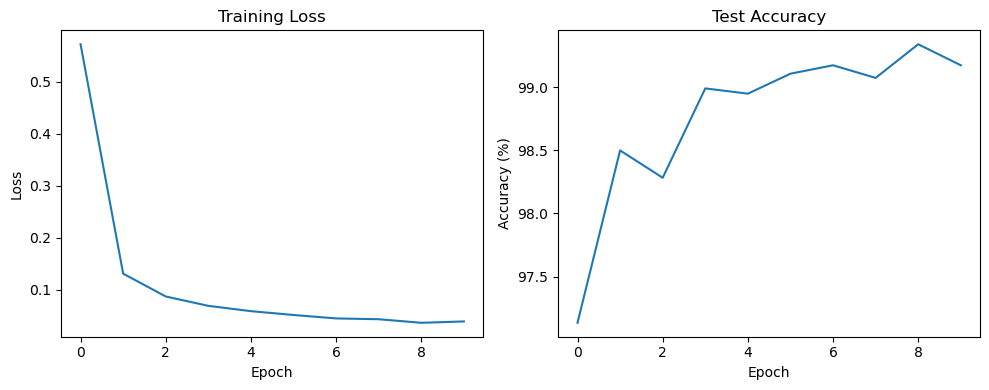

In [9]:
# CNN 
import matplotlib.pyplot as plt

# CNN-A：Training Loss & Test Accuracy
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(loss_list, label='Train Loss')
plt.title("Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.subplot(1,2,2)
plt.plot([a*100 for a in acc_list], label='Test Accuracy')
plt.title("Test Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.tight_layout()
plt.show()

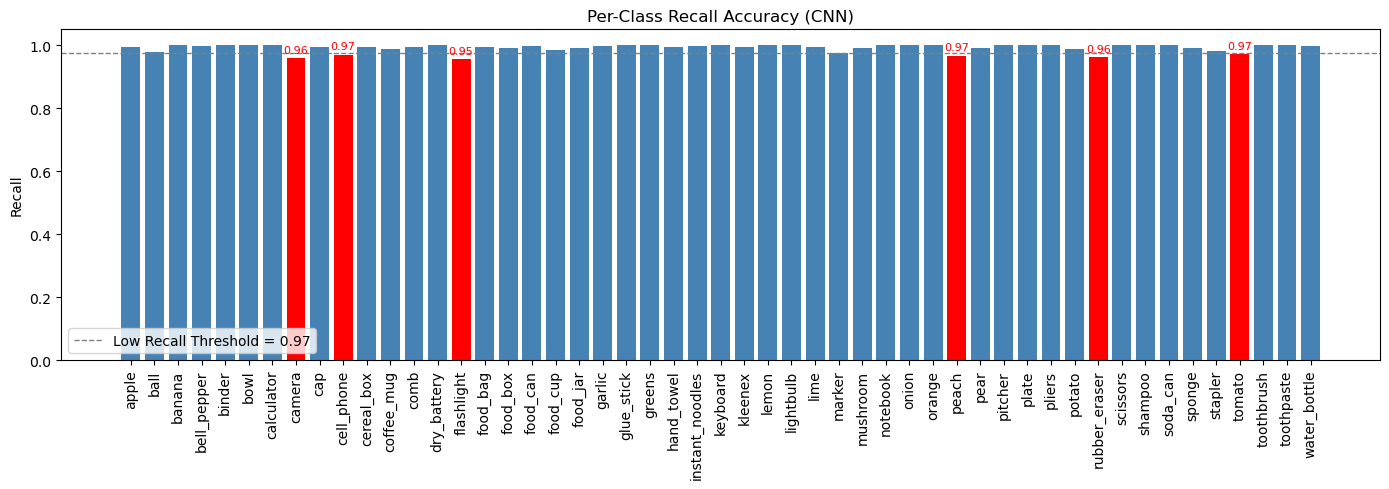

In [10]:
# CNN-D & E：Per-class Accuracy & Confusion Matrix
all_preds, all_labels = [], []
resnet_model.eval()
with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)
        outputs = resnet_model(inputs)
        preds = torch.argmax(outputs, 1).cpu().numpy()
        all_preds.extend(preds)
        all_labels.extend(labels.numpy())
        
# 生成 classification_report 字典
report = classification_report(all_labels, all_preds, target_names=classes, output_dict=True)
accs = np.array([report[c]['recall'] for c in classes])

# 计算平均值与标准差
mean_recall = accs.mean()
std_recall = accs.std()
threshold = mean_recall - 1.5 * std_recall

# 设置颜色：明显偏低的用红色，其余用蓝色
colors = ['red' if acc < threshold else 'steelblue' for acc in accs]

# 绘图
plt.figure(figsize=(14, 5))
bars = plt.bar(classes, accs, color=colors)
plt.xticks(rotation=90)
plt.ylim(0, 1.05)
plt.ylabel("Recall")
plt.title("Per-Class Recall Accuracy (CNN)")

# 标出明显偏低的 recall 值
for i, bar in enumerate(bars):
    if accs[i] < threshold:
        plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.01,
                 f"{accs[i]:.2f}", ha='center', va='bottom', fontsize=8, color='red')

# 添加参考线
plt.axhline(threshold, color='gray', linestyle='--', linewidth=1, label=f"Low Recall Threshold = {threshold:.2f}")
plt.legend()

plt.tight_layout()
plt.show()

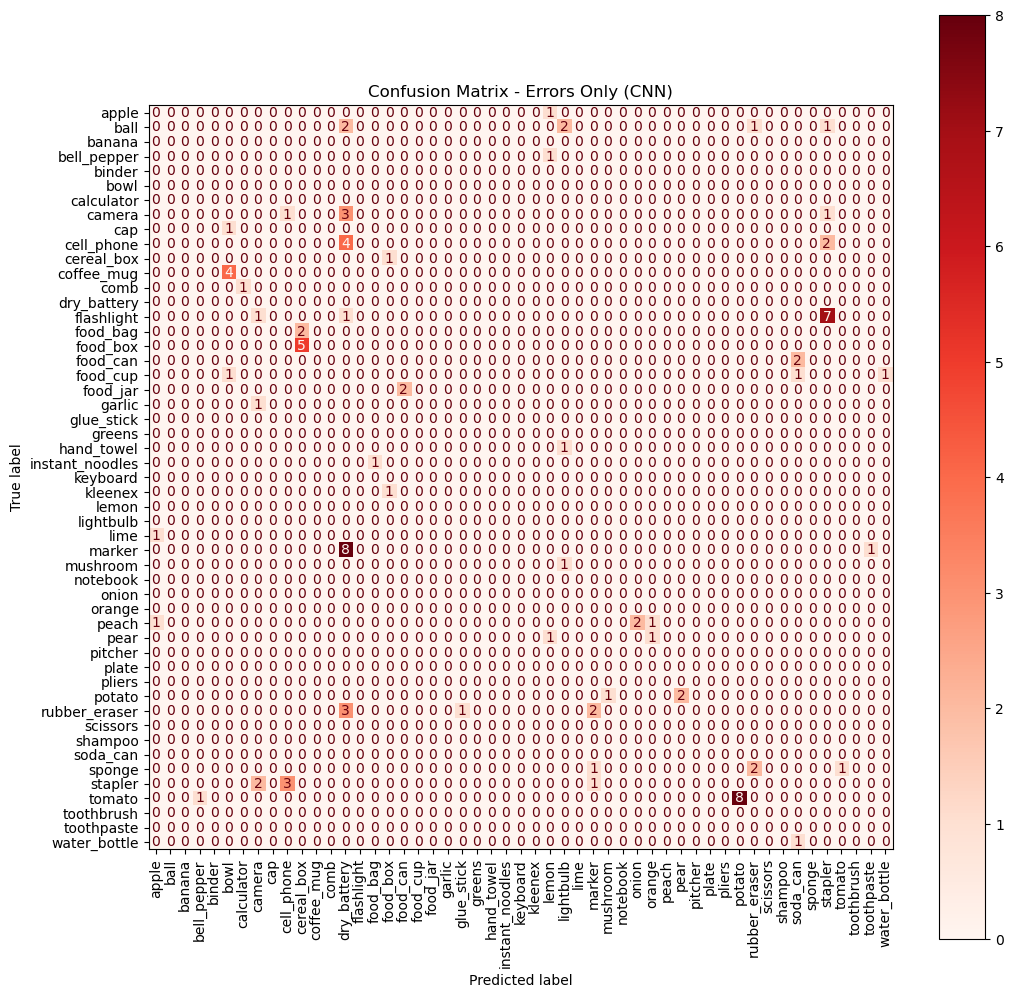

In [11]:
# confusion matrix
cm = confusion_matrix(all_labels, all_preds)
# Create a copy and set the diagonal to 0 (only keep misclassifications)
cm_errors_only = cm.copy()
np.fill_diagonal(cm_errors_only, 0)
# Display the confusion matrix for misclassified parts.
disp = ConfusionMatrixDisplay(confusion_matrix=cm_errors_only, display_labels=classes)
fig, ax = plt.subplots(figsize=(12, 12))  
disp.plot(ax=ax, cmap='Reds', xticks_rotation=90, values_format='d')
plt.title("Confusion Matrix - Errors Only (CNN)")
plt.show()

In [12]:
import torch
print("Using device:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU only")

Using device: NVIDIA GeForce RTX 4080 Laptop GPU


In [13]:
# Hyperparameter Exploration Extension Module
import time
import torch
from torchvision.models import resnet18, ResNet18_Weights
from torch.utils.data import DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

param_grid = {
    'lr': [0.001, 0.0001],
    'optimizer': ['adam', 'sgd'],
    'batch_size': [32, 64]
}

results = []

# === Define training function with device-aware tensors ===
def train_model(model, criterion, optimizer, train_loader, test_loader, epochs=5):
    acc_list = []

    for epoch in range(epochs):
        model.train()
        for inputs, labels in train_loader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

        # Evaluation
        model.eval()
        correct, total = 0, 0
        with torch.no_grad():
            for inputs, labels in test_loader:
                inputs = inputs.to(device)
                labels = labels.to(device)
                outputs = model(inputs)
                _, preds = torch.max(outputs, 1)
                correct += (preds == labels).sum().item()
                total += labels.size(0)

        acc = 100 * correct / total
        print(f"Epoch {epoch+1}/{epochs} | Test Acc: {acc:.2f}%")
        acc_list.append(acc)

    return model, optimizer, acc_list

# === Grid search ===
for lr in param_grid['lr']:
    for opt in param_grid['optimizer']:
        for bs in param_grid['batch_size']:
            print(f"\nCurrent combination: LR={lr}, OPT={opt.upper()}, BATCH={bs}")
            start = time.time()

            # Load ResNet18 with updated weights API
            weights = ResNet18_Weights.DEFAULT
            model = resnet18(weights=weights)

            # Freeze backbone
            for param in model.parameters():
                param.requires_grad = False

            # Replace classification head
            model.fc = nn.Linear(model.fc.in_features, num_classes)
            model = model.to(device)

            # Optimizer
            if opt == 'adam':
                optimizer = optim.Adam(model.fc.parameters(), lr=lr)
            else:
                optimizer = optim.SGD(model.fc.parameters(), lr=lr, momentum=0.9)

            # Data loaders with workers
            train_loader = DataLoader(train_dataset, batch_size=bs, shuffle=True,
                                      pin_memory=True, num_workers=4)
            test_loader = DataLoader(test_dataset, batch_size=bs, shuffle=False,
                                     pin_memory=True, num_workers=4)

            # Train
            _, _, acc_list = train_model(model, criterion, optimizer, train_loader, test_loader, epochs=5)

            # Save results
            results.append({
                'lr': lr,
                'optimizer': opt,
                'batch_size': bs,
                'final_acc': acc_list[-1]
            })

            print(f"✔ Done in {(time.time() - start) / 60:.2f} min")

Using device: cuda

Current combination: LR=0.001, OPT=ADAM, BATCH=32
Epoch 1/5 | Test Acc: 96.86%
Epoch 2/5 | Test Acc: 98.33%
Epoch 3/5 | Test Acc: 98.84%
Epoch 4/5 | Test Acc: 98.58%
Epoch 5/5 | Test Acc: 98.98%
✔ Done in 13.55 min

Current combination: LR=0.001, OPT=ADAM, BATCH=64
Epoch 1/5 | Test Acc: 96.49%
Epoch 2/5 | Test Acc: 98.13%
Epoch 3/5 | Test Acc: 98.61%
Epoch 4/5 | Test Acc: 98.97%
Epoch 5/5 | Test Acc: 98.91%
✔ Done in 13.21 min

Current combination: LR=0.001, OPT=SGD, BATCH=32
Epoch 1/5 | Test Acc: 91.81%
Epoch 2/5 | Test Acc: 95.32%
Epoch 3/5 | Test Acc: 96.54%
Epoch 4/5 | Test Acc: 97.09%
Epoch 5/5 | Test Acc: 97.56%
✔ Done in 13.32 min

Current combination: LR=0.001, OPT=SGD, BATCH=64
Epoch 1/5 | Test Acc: 86.76%
Epoch 2/5 | Test Acc: 91.62%
Epoch 3/5 | Test Acc: 94.53%
Epoch 4/5 | Test Acc: 95.18%
Epoch 5/5 | Test Acc: 96.12%
✔ Done in 13.21 min

Current combination: LR=0.0001, OPT=ADAM, BATCH=32
Epoch 1/5 | Test Acc: 84.24%
Epoch 2/5 | Test Acc: 91.59%
Epoch 3/5

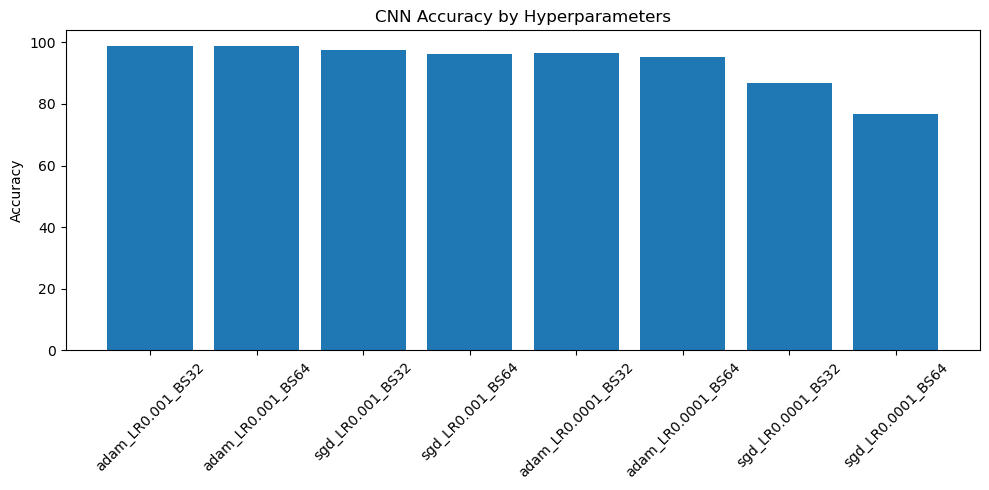

In [14]:
# visualization module

df = pd.DataFrame(results)
df['label'] = df['optimizer'] + "_LR" + df['lr'].astype(str) + "_BS" + df['batch_size'].astype(str)

# bar chart
plt.figure(figsize=(10, 5))
plt.bar(df['label'], df['final_acc'])
plt.xticks(rotation=45)
plt.ylabel("Accuracy")
plt.title("CNN Accuracy by Hyperparameters")
plt.tight_layout()
plt.show()

In [15]:
duplicates = df.duplicated(subset=['batch_size', 'lr'])
print(df[duplicates])

       lr optimizer  batch_size  final_acc              label
2  0.0010       sgd          32  97.558333   sgd_LR0.001_BS32
3  0.0010       sgd          64  96.125000   sgd_LR0.001_BS64
6  0.0001       sgd          32  86.883333  sgd_LR0.0001_BS32
7  0.0001       sgd          64  76.691667  sgd_LR0.0001_BS64


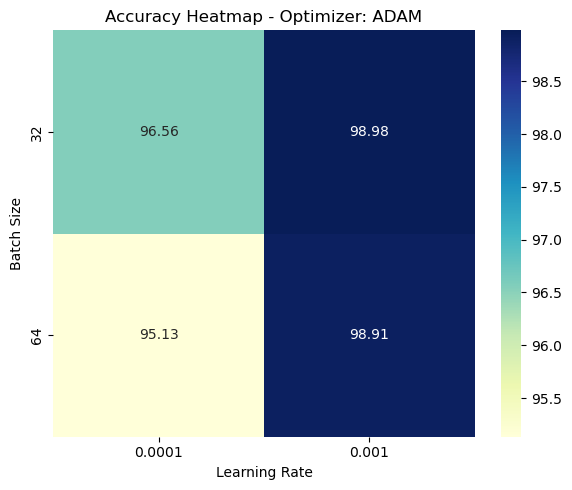

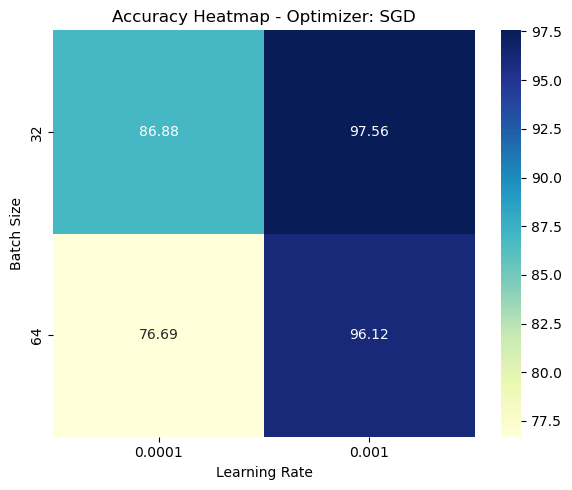

In [16]:
# heatmap
# Loop through each optimizer
for opt in df['optimizer'].unique():
    sub_df = df[df['optimizer'] == opt]  # 选中当前优化器的数据

    # 生成 heatmap 所需格式（行=batch_size，列=lr）
    heatmap_data = sub_df.pivot(index='batch_size', columns='lr', values='final_acc')

    # 画图
    plt.figure(figsize=(6, 5))
    sns.heatmap(heatmap_data, annot=True, cmap="YlGnBu", fmt=".2f")
    plt.title(f"Accuracy Heatmap - Optimizer: {opt.upper()}")
    plt.xlabel("Learning Rate")
    plt.ylabel("Batch Size")
    plt.tight_layout()
    plt.show()

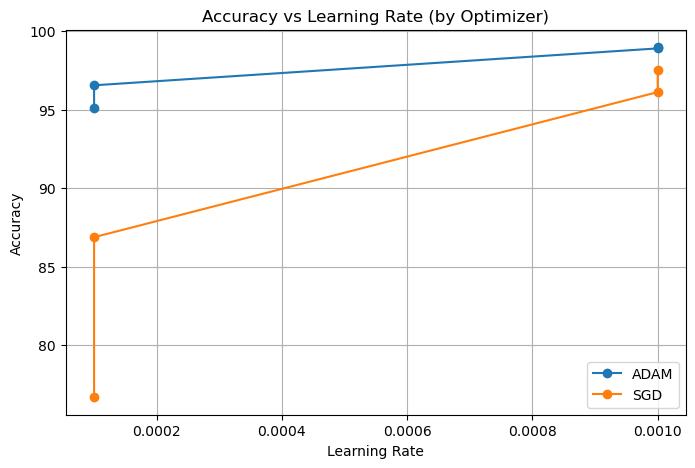

In [17]:
# Line chart: Accuracy vs Learning Rate (by optimizer)
plt.figure(figsize=(8, 5))
for opt in df['optimizer'].unique():
    subset = df[df['optimizer'] == opt]
    plt.plot(subset['lr'], subset['final_acc'], marker='o', label=opt.upper())
plt.xlabel("Learning Rate")
plt.ylabel("Accuracy")
plt.title("Accuracy vs Learning Rate (by Optimizer)")
plt.legend()
plt.grid(True)
plt.show()

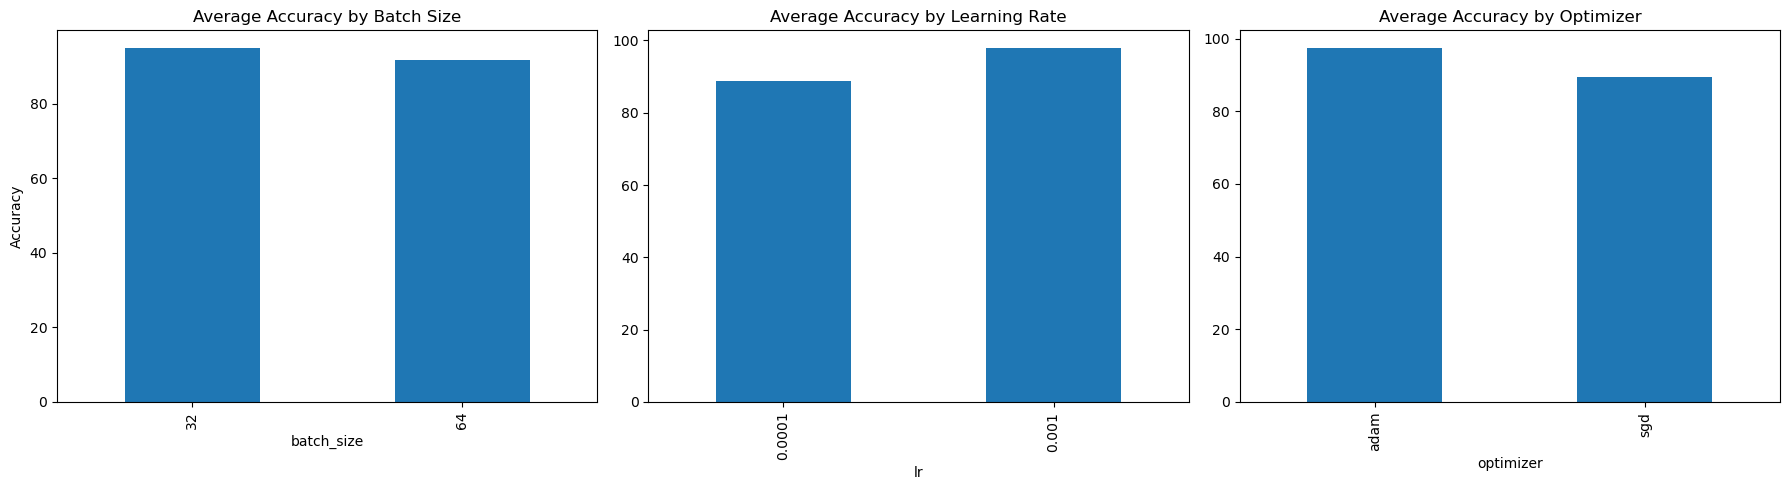

In [18]:
# Multiple subplots to show the influence of different hyperparameters.
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# batch size
df.groupby('batch_size')['final_acc'].mean().plot(kind='bar', ax=axes[0])
axes[0].set_title("Average Accuracy by Batch Size")
axes[0].set_ylabel("Accuracy")

# learning rate
df.groupby('lr')['final_acc'].mean().plot(kind='bar', ax=axes[1])
axes[1].set_title("Average Accuracy by Learning Rate")

# optimizer
df.groupby('optimizer')['final_acc'].mean().plot(kind='bar', ax=axes[2])
axes[2].set_title("Average Accuracy by Optimizer")

plt.tight_layout()
plt.show()

In [19]:
# Custom CNN model: 5 blocks, each block consists of 1 convolutional layer + Batch Normalization + ReLU + Max Pooling
import torch.nn as nn

class CustomCNN(nn.Module):
    def __init__(self, num_classes):
        super(CustomCNN, self).__init__()
        self.features = nn.Sequential(
            # Block 1
            nn.Conv2d(3, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Block 2
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Block 3
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Block 4
            nn.Conv2d(256, 512, kernel_size=3, padding=1),
            nn.BatchNorm2d(512),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Block 5
            nn.Conv2d(512, 512, kernel_size=3, padding=1),
            nn.BatchNorm2d(512),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(512 * 7 * 7, 512),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(512, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


In [20]:
# model tranning
custom_model = CustomCNN(num_classes).to(device)
optimizer = optim.Adam(custom_model.parameters(), lr=0.001)
criterion = nn.CrossEntropyLoss()

custom_model, custom_loss, custom_acc = train_model(custom_model, criterion, optimizer, train_loader, test_loader, epochs=10)
custom_train_acc = evaluate_accuracy(custom_model, train_loader, device)
custom_test_acc = evaluate_accuracy(custom_model, test_loader, device)
torch.save(custom_model.state_dict(), "custom_cnn.pth")
print("CNN custom_cnn.pth")

# saving CustomCNN 准确率
custom_df = pd.DataFrame([{
    'Model': 'CustomCNN',
    'Train Accuracy': round(custom_train_acc * 100, 2),
    'Test Accuracy': round(custom_test_acc * 100, 2)
}])
custom_df.to_csv("customcnn_accuracy.csv", index=False)
print(" CustomCNN saving customcnn_accuracy.csv")
print(custom_df)

Epoch 1/10 | Test Acc: 53.99%
Epoch 2/10 | Test Acc: 60.52%
Epoch 3/10 | Test Acc: 67.45%
Epoch 4/10 | Test Acc: 72.88%
Epoch 5/10 | Test Acc: 79.52%
Epoch 6/10 | Test Acc: 88.63%
Epoch 7/10 | Test Acc: 86.92%
Epoch 8/10 | Test Acc: 93.38%
Epoch 9/10 | Test Acc: 95.15%
Epoch 10/10 | Test Acc: 95.78%
CNN custom_cnn.pth
 CustomCNN saving customcnn_accuracy.csv
       Model  Train Accuracy  Test Accuracy
0  CustomCNN           95.19          95.78


In [21]:
#  Hyperparameter Exploration Module (based on CustomCNN)
param_grid = {
    'lr': [0.001, 0.0001],
    'optimizer': ['adam', 'sgd'],
    'batch_size': [32, 64]
}

results = []
log_records = []  # To store per-epoch loss and accuracy

for lr in param_grid['lr']:
    for opt in param_grid['optimizer']:
        for bs in param_grid['batch_size']:
            print(f"\n Current combination: LR={lr}, OPT={opt.upper()}, BATCH={bs}")

            model = CustomCNN(num_classes).to(device)

            if opt == 'adam':
                optimizer = optim.Adam(model.parameters(), lr=lr)
            else:
                optimizer = optim.SGD(model.parameters(), lr=lr, momentum=0.9)

            train_loader = DataLoader(train_dataset, batch_size=bs, shuffle=True, pin_memory=True)
            test_loader = DataLoader(test_dataset, batch_size=bs, shuffle=False, pin_memory=True)

            #  Train and log loss/accuracy per epoch
            acc_list = []
            loss_list = []

            for epoch in range(5):
                model.train()
                running_loss = 0.0

                for inputs, labels in train_loader:
                    inputs = inputs.to(device)
                    labels = labels.to(device)

                    optimizer.zero_grad()
                    outputs = model(inputs)
                    loss = criterion(outputs, labels)
                    loss.backward()
                    optimizer.step()

                    running_loss += loss.item()

                avg_loss = running_loss / len(train_loader)

                model.eval()
                correct, total = 0, 0
                with torch.no_grad():
                    for inputs, labels in test_loader:
                        inputs = inputs.to(device)
                        labels = labels.to(device)
                        outputs = model(inputs)
                        _, preds = torch.max(outputs, 1)
                        correct += (preds == labels).sum().item()
                        total += labels.size(0)

                acc = 100 * correct / total
                acc_list.append(acc)
                loss_list.append(avg_loss)

                print(f"Epoch {epoch+1}/5 | Loss: {avg_loss:.4f} | Accuracy: {acc:.2f}%")

                # Save each epoch record
                log_records.append({
                    'lr': lr,
                    'optimizer': opt,
                    'batch_size': bs,
                    'epoch': epoch + 1,
                    'loss': avg_loss,
                    'accuracy': acc
                })

            # Save final result per combination for summary plots
            results.append({
                'lr': lr,
                'optimizer': opt,
                'batch_size': bs,
                'final_acc': acc_list[-1]
            })

# Save full epoch logs to CSV
log_df = pd.DataFrame(log_records)
log_df.to_csv("training_log.csv", index=False)
print("📄 training_log.csv saved successfully.")


 Current combination: LR=0.001, OPT=ADAM, BATCH=32
Epoch 1/5 | Loss: 3.2322 | Accuracy: 39.78%
Epoch 2/5 | Loss: 2.4310 | Accuracy: 66.55%
Epoch 3/5 | Loss: 2.0491 | Accuracy: 77.02%
Epoch 4/5 | Loss: 1.7885 | Accuracy: 81.75%
Epoch 5/5 | Loss: 1.6104 | Accuracy: 87.17%

 Current combination: LR=0.001, OPT=ADAM, BATCH=64
Epoch 1/5 | Loss: 3.2258 | Accuracy: 44.58%
Epoch 2/5 | Loss: 2.3614 | Accuracy: 59.61%
Epoch 3/5 | Loss: 2.0799 | Accuracy: 68.31%
Epoch 4/5 | Loss: 1.8847 | Accuracy: 80.22%
Epoch 5/5 | Loss: 1.7239 | Accuracy: 86.21%

 Current combination: LR=0.001, OPT=SGD, BATCH=32
Epoch 1/5 | Loss: 0.9115 | Accuracy: 96.35%
Epoch 2/5 | Loss: 0.1993 | Accuracy: 99.19%
Epoch 3/5 | Loss: 0.1129 | Accuracy: 99.83%
Epoch 4/5 | Loss: 0.0780 | Accuracy: 99.79%
Epoch 5/5 | Loss: 0.0559 | Accuracy: 99.92%

 Current combination: LR=0.001, OPT=SGD, BATCH=64
Epoch 1/5 | Loss: 1.0728 | Accuracy: 97.57%
Epoch 2/5 | Loss: 0.2223 | Accuracy: 99.28%
Epoch 3/5 | Loss: 0.1147 | Accuracy: 99.77%
Ep

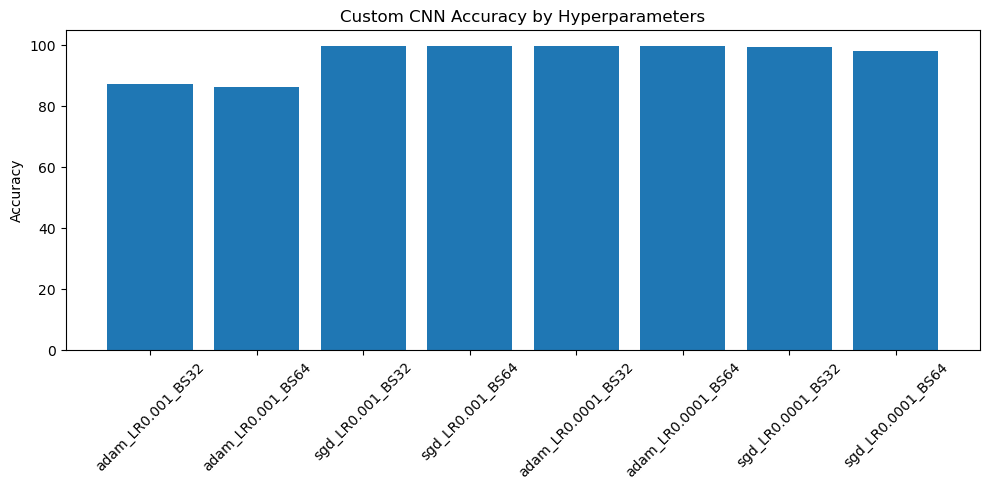

In [22]:
# Visualization module (bar chart, heat map, line chart, subplot)
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# DataFrame
df = pd.DataFrame(results)
df['label'] = df['optimizer'] + "_LR" + df['lr'].astype(str) + "_BS" + df['batch_size'].astype(str)

# bar chart
plt.figure(figsize=(10, 5))
plt.bar(df['label'], df['final_acc'])
plt.xticks(rotation=45)
plt.ylabel("Accuracy")
plt.title("Custom CNN Accuracy by Hyperparameters")
plt.tight_layout()
plt.show()

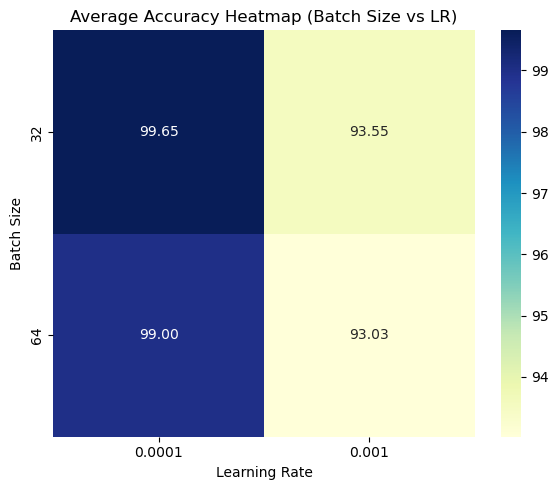

In [23]:
# Heatmap with automatic averaging of duplicates
heatmap_data = df.pivot_table(index='batch_size', columns='lr', values='final_acc', aggfunc='mean')

plt.figure(figsize=(6, 5))
sns.heatmap(heatmap_data, annot=True, cmap="YlGnBu", fmt=".2f")
plt.title("Average Accuracy Heatmap (Batch Size vs LR)")
plt.xlabel("Learning Rate")
plt.ylabel("Batch Size")
plt.tight_layout()
plt.show()

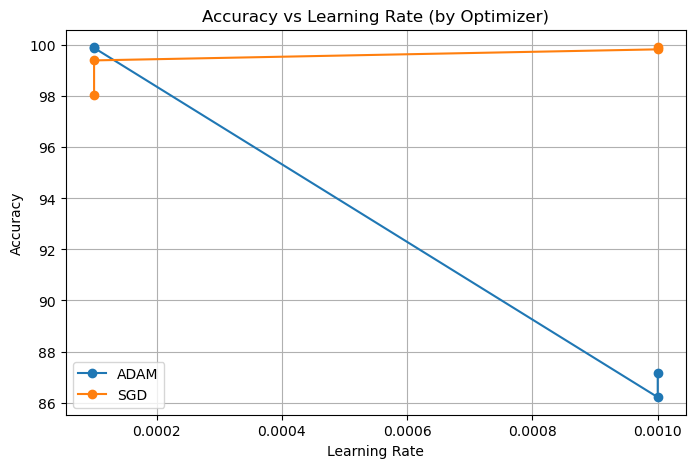

In [24]:
# line chart
plt.figure(figsize=(8, 5))
for opt in df['optimizer'].unique():
    subset = df[df['optimizer'] == opt]
    plt.plot(subset['lr'], subset['final_acc'], marker='o', label=opt.upper())
plt.xlabel("Learning Rate")
plt.ylabel("Accuracy")
plt.title("Accuracy vs Learning Rate (by Optimizer)")
plt.legend()
plt.grid(True)
plt.show()


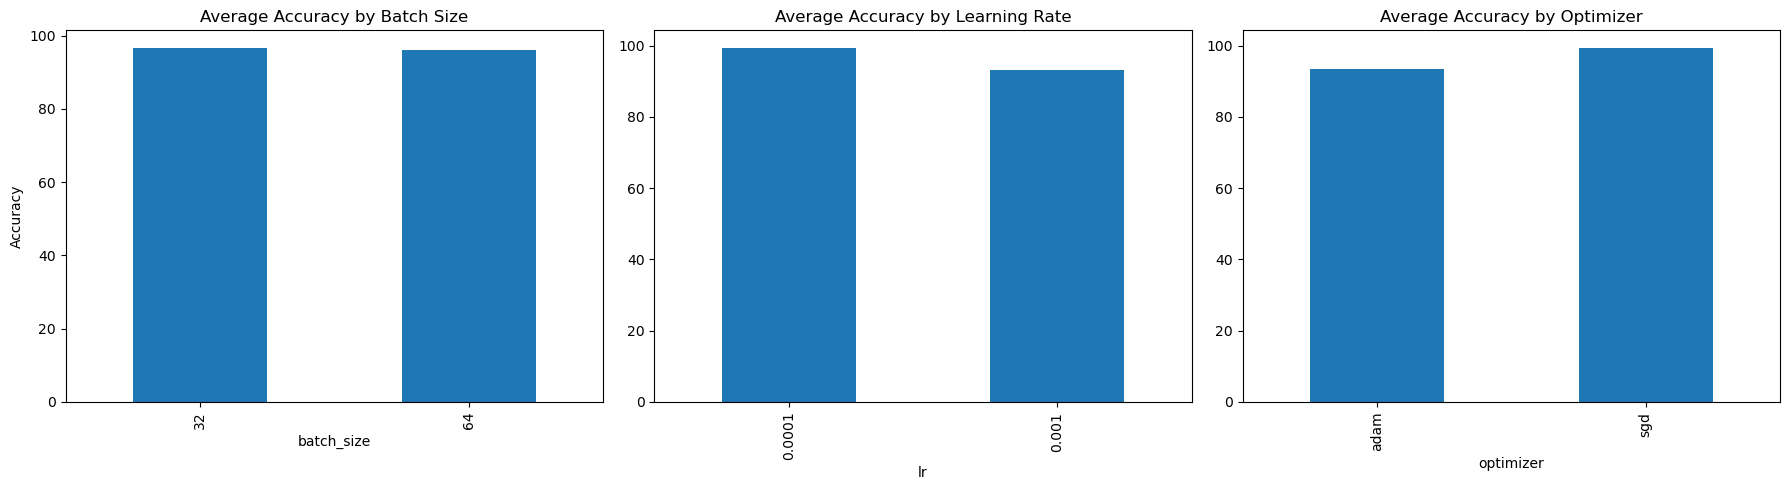

In [25]:
# Multiple subplots display the average effect of hyperparameters.
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
df.groupby('batch_size')['final_acc'].mean().plot(kind='bar', ax=axes[0])
axes[0].set_title("Average Accuracy by Batch Size")
axes[0].set_ylabel("Accuracy")

df.groupby('lr')['final_acc'].mean().plot(kind='bar', ax=axes[1])
axes[1].set_title("Average Accuracy by Learning Rate")

df.groupby('optimizer')['final_acc'].mean().plot(kind='bar', ax=axes[2])
axes[2].set_title("Average Accuracy by Optimizer")
plt.tight_layout()
plt.show()

[local path]/719825042.py:12: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(
[local path]/719825042.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
[local path]/719825042.py:26: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(
[local path]/719825042.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
[local path]/719825042.py:40: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(
[local path]/719825042.py:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.1

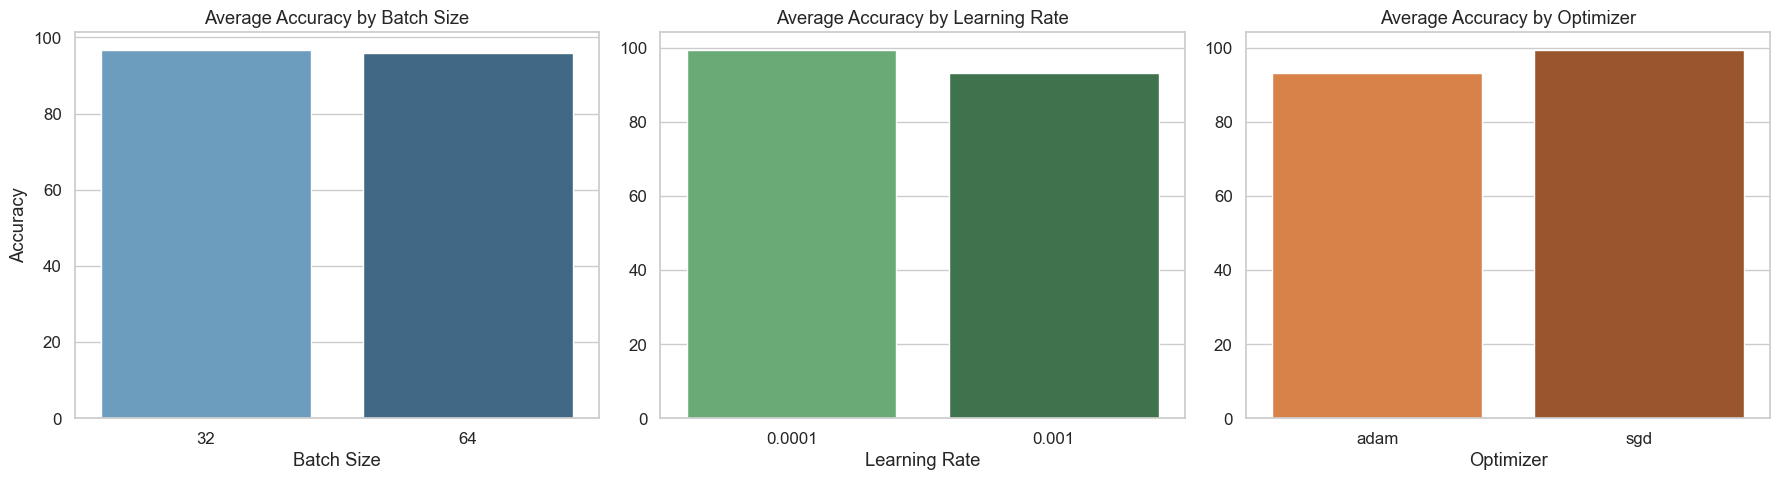

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Optional: set seaborn style
sns.set(style="whitegrid", font_scale=1.1)

# Create subplots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# === Subplot 1: Batch Size ===
sns.barplot(
    data=df, 
    x='batch_size', 
    y='final_acc', 
    estimator='mean', 
    ci=None, 
    ax=axes[0], 
    palette='Blues_d'
)
axes[0].set_title("Average Accuracy by Batch Size")
axes[0].set_xlabel("Batch Size")
axes[0].set_ylabel("Accuracy")

# === Subplot 2: Learning Rate ===
sns.barplot(
    data=df, 
    x='lr', 
    y='final_acc', 
    estimator='mean', 
    ci=None, 
    ax=axes[1], 
    palette='Greens_d'
)
axes[1].set_title("Average Accuracy by Learning Rate")
axes[1].set_xlabel("Learning Rate")
axes[1].set_ylabel("")

# === Subplot 3: Optimizer ===
sns.barplot(
    data=df, 
    x='optimizer', 
    y='final_acc', 
    estimator='mean', 
    ci=None, 
    ax=axes[2], 
    palette='Oranges_d'
)
axes[2].set_title("Average Accuracy by Optimizer")
axes[2].set_xlabel("Optimizer")
axes[2].set_ylabel("")

# === Final layout and save ===
plt.tight_layout()
plt.savefig("hyperparameter_accuracy_summary.png", dpi=300)  # 🔽 Export to high-res PNG
plt.show()